In [ ]:
import os
import sys

# Run from the project root so `src` imports and relative data paths resolve.
if os.path.basename(os.getcwd()) == "jupyter_notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [1]:
import numpy as np
import torch 
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from src.true_constitutive_law import KinematicHardeningPlasticity
from src.ou_trajectories import generate_ou_trajectories, smooth_ou_trajectories
from src.neural_variational_ode import Dissipation, Energy, VariationalODESolver
from torch.utils.data import TensorDataset, DataLoader


In [2]:
params = {'font.family': 'serif',
          'font.sans-serif': 'Times New Roman',
          'font.size': 14,
          'lines.linewidth': 2,
          'text.usetex': False,
          'xtick.top': True,
          'xtick.minor.visible': True,
          'ytick.minor.visible': True,
          'xtick.direction': 'in',
          'xtick.major.top': True,
          'xtick.major.bottom': True,
          'xtick.minor.top': True,
          'xtick.minor.bottom': True,
          'xtick.minor.width': 1,
          'xtick.major.width': 1,
          'xtick.minor.size': 3, 
          'xtick.major.size': 6,
          'ytick.right': True,
          'ytick.direction': 'in',
          'ytick.major.left': True,
          'ytick.major.right': True,
          'ytick.minor.left': True,
          'ytick.minor.right': True,
          'ytick.minor.width': 1,
          'ytick.major.width': 1,
          'ytick.minor.size': 3,
          'ytick.major.size': 6,
          'legend.frameon': False,
          'lines.markersize': 4.0,
          'axes.formatter.use_mathtext': True,
          'text.latex.preamble' : r'\usepackage{amsmath}',
          'text.usetex': True}
plt.rcParams.update(params)

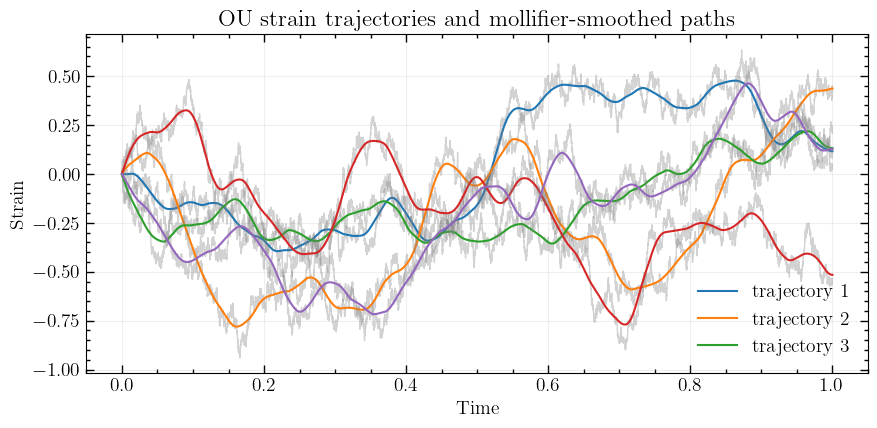

In [11]:
# 1. Sample strain trajectories with an OU process.
n_trajectories = 64
T = 1.0
dt = 1.0 / 10000.0
theta = 3.0
mu = 0.0
sigma = 1
x0 = 0.0

# 2. Smooth the sampled strain using the mollifier convolution.
mollifier_window = 601
times, strain_trajectories = generate_ou_trajectories(
    theta=theta,
    mu=mu,
    sigma=sigma,
    x0=x0,
    n_trajectories=n_trajectories,
    T=T,
    dt=dt,
    seed=41,
)
strain_trajectories_smooth = smooth_ou_trajectories(
    strain_trajectories,
    window_size=mollifier_window,
)

# 3. Visualize a few raw and smoothed strain trajectories.
fig, ax = plt.subplots(figsize=(9, 4.5))
for trajectory_index in range(min(5, n_trajectories)):
    ax.plot(
        times,
        strain_trajectories[trajectory_index],
        color="tab:gray",
        alpha=0.35,
        linewidth=1.0,
    )
    ax.plot(
        times,
        strain_trajectories_smooth[trajectory_index],
        linewidth=1.5,
        label=f"trajectory {trajectory_index + 1}" if trajectory_index < 3 else None,
    )
ax.set_xlabel("Time")
ax.set_ylabel("Strain")
ax.set_title("OU strain trajectories and mollifier-smoothed paths")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


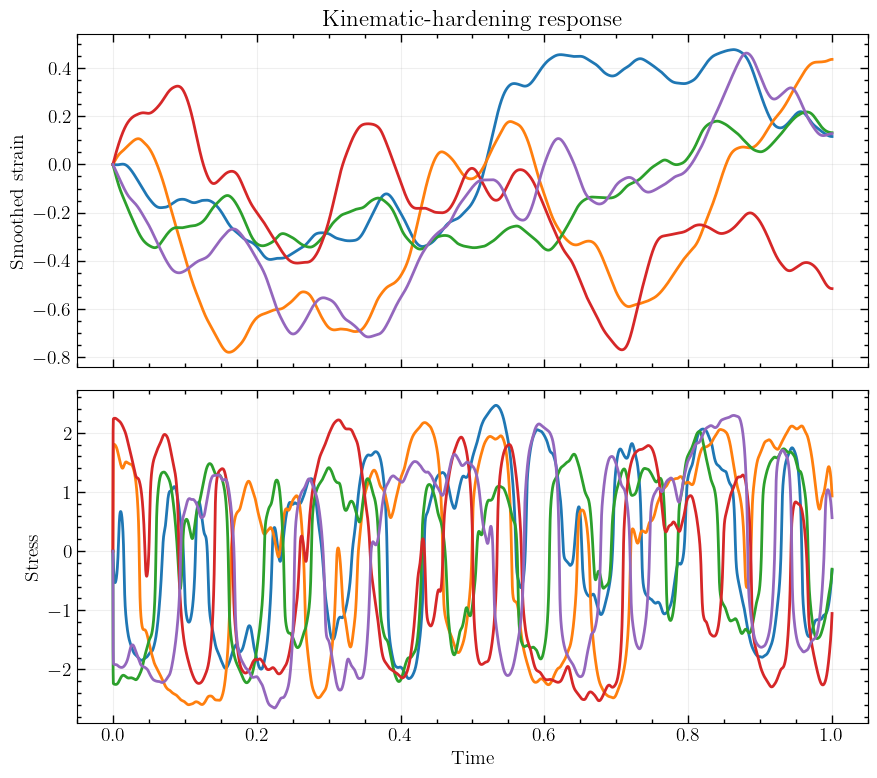

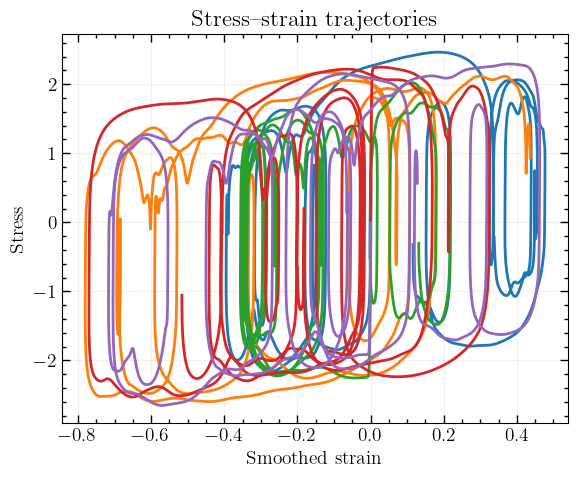

In [12]:
# 4. Solve for stress with the kinematic-hardening model.
E = 1000.0
H = 1.0
sigma_y = 1
rate_exponent = 0.5
kinematic_model = KinematicHardeningPlasticity(
    node_count=1,
    model_dt=dt,
    m=rate_exponent,
    E=E,
    H=H,
    sigma_y=sigma_y,
)

stress_trajectories = np.empty_like(strain_trajectories_smooth)
plastic_strain_trajectories = np.empty_like(strain_trajectories_smooth)
for trajectory_index, strain_path in enumerate(strain_trajectories_smooth):
    plastic_strain, stress_path = kinematic_model.stress_history(
        strain_path[:, np.newaxis]
    )
    plastic_strain_trajectories[trajectory_index] = plastic_strain[:, 0]
    stress_trajectories[trajectory_index] = stress_path[:, 0]

# 5. Visualize stress and strain histories, and the stress--strain response.
fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
for trajectory_index in range(min(5, n_trajectories)):
    axes[0].plot(times, strain_trajectories_smooth[trajectory_index])
    axes[1].plot(times, stress_trajectories[trajectory_index])
axes[0].set_ylabel("Smoothed strain")
axes[1].set_ylabel("Stress")
axes[1].set_xlabel("Time")
axes[0].set_title("Kinematic-hardening response")
for axis in axes:
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for trajectory_index in range(min(5, n_trajectories)):
    ax.plot(
        strain_trajectories_smooth[trajectory_index],
        stress_trajectories[trajectory_index],
    )
ax.set_xlabel("Smoothed strain")
ax.set_ylabel("Stress")
ax.set_title("Stress--strain trajectories")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [13]:
# 6. Learn W and D from the strain and stress samples without normalization.
strain_tensor = torch.as_tensor(strain_trajectories_smooth, dtype=torch.float32)
plastic_strain_tensor = torch.as_tensor(plastic_strain_trajectories, dtype=torch.float32)
stress_tensor = torch.as_tensor(stress_trajectories, dtype=torch.float32)
training_dataset = TensorDataset(strain_tensor, plastic_strain_tensor, stress_tensor)
train_loader = DataLoader(training_dataset, batch_size=16, shuffle=True)

energy_model = Energy(e_dim=1, xi_dim=1, hidden_sizes=(64,))
dissipation_model = Dissipation(xi_dim=1, hidden_sizes=(64,))
variational_solver = VariationalODESolver(energy_model, dissipation_model)
optimizer = torch.optim.Adam(variational_solver.parameters(), lr=1e-2)
loss_function = torch.nn.MSELoss()
training_losses = []

In [26]:

n_epochs = 100
for epoch in tqdm(range(n_epochs), desc="Adjoint training", unit="epoch"):
    epoch_loss = 0.0
    for strain_batch, _, stress_batch in train_loader:
        optimizer.zero_grad()
        loss, gradients, _, _ = variational_solver.compute_adjoint_gradients(
            strain_batch,
            stress_batch,
            dt=dt,
        )
        for parameter, gradient in zip(variational_solver.parameters(), gradients):
            parameter.grad = gradient / stress_batch.numel()
        optimizer.step()
        epoch_loss += (loss.item() / stress_batch.numel()) * strain_batch.shape[0]
    epoch_loss /= len(training_dataset)
    training_losses.append(epoch_loss)
    tqdm.write(f"Epoch {epoch + 1:3d}/{n_epochs}: loss = {epoch_loss:.6e}")
variational_solver.eval()

Adjoint training:   0%|          | 0/100 [00:00<?, ?epoch/s]

Epoch   1/100: loss = 3.924204e-07
Epoch   2/100: loss = 3.877740e-07
Epoch   3/100: loss = 3.837293e-07
Epoch   4/100: loss = 3.794692e-07
Epoch   5/100: loss = 3.738599e-07
Epoch   6/100: loss = 3.706031e-07
Epoch   7/100: loss = 3.656947e-07
Epoch   8/100: loss = 3.623318e-07
Epoch   9/100: loss = 3.579867e-07
Epoch  10/100: loss = 3.523011e-07
Epoch  11/100: loss = 3.490235e-07
Epoch  12/100: loss = 3.444990e-07
Epoch  13/100: loss = 3.398222e-07
Epoch  14/100: loss = 3.353847e-07
Epoch  15/100: loss = 3.313331e-07
Epoch  16/100: loss = 3.277219e-07
Epoch  17/100: loss = 3.236397e-07
Epoch  18/100: loss = 3.198945e-07
Epoch  19/100: loss = 3.160473e-07
Epoch  20/100: loss = 3.126763e-07
Epoch  21/100: loss = 3.093106e-07
Epoch  22/100: loss = 3.055902e-07
Epoch  23/100: loss = 3.025498e-07
Epoch  24/100: loss = 2.985997e-07
Epoch  25/100: loss = 2.953308e-07
Epoch  26/100: loss = 2.922359e-07
Epoch  27/100: loss = 2.887074e-07
Epoch  28/100: loss = 2.856774e-07
Epoch  29/100: loss 

VariationalODESolver(
  (energy): Energy(
    (elastic_network): InputConvexNetwork(
      (input_layers): ModuleList(
        (0): Linear(in_features=1, out_features=64, bias=False)
      )
      (state_layers): ModuleList(
        (0): Identity()
      )
      (output_input): Linear(in_features=1, out_features=1, bias=False)
      (output_state): _PositiveLinear(
        (activation): ReLUS()
      )
    )
    (inelastic_network): InputConvexNetwork(
      (input_layers): ModuleList(
        (0): Linear(in_features=1, out_features=64, bias=False)
      )
      (state_layers): ModuleList(
        (0): Identity()
      )
      (output_input): Linear(in_features=1, out_features=1, bias=False)
      (output_state): _PositiveLinear(
        (activation): ReLUS()
      )
    )
  )
  (dissipation): Dissipation(
    (network): InputConvexNetwork(
      (input_layers): ModuleList(
        (0): Linear(in_features=1, out_features=64, bias=True)
      )
      (state_layers): ModuleList(
        

In [27]:
with torch.enable_grad():
    xi_learned, stress_learned = variational_solver.solve(
        strain_tensor,
        dt=dt,
        create_graph=False,
    )
stress_learned = stress_learned.detach().cpu().numpy()
xi_learned = xi_learned.detach().cpu().numpy()


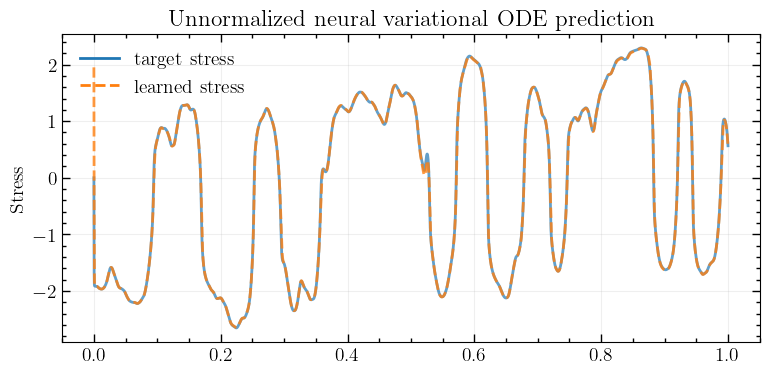

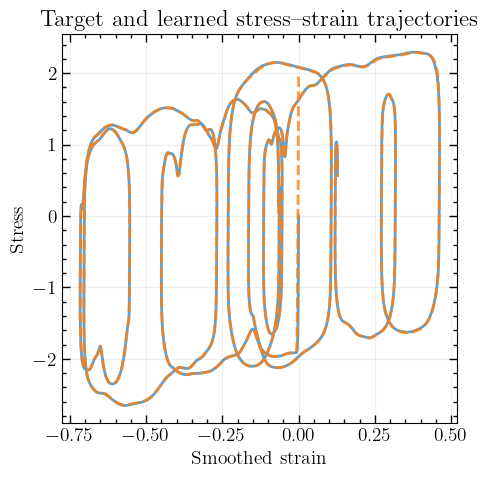

In [28]:
time_fig, time_ax = plt.subplots(1, 1, figsize=(9, 4), sharex=True)
strain_fig, strain_ax = plt.subplots(1, 1, figsize=(5, 5), sharex=True)

for trajectory_index in range(4,5):
    time_ax.plot(times, stress_trajectories[trajectory_index], color="tab:blue", alpha=0.7)
    time_ax.plot(times, stress_learned[trajectory_index], color="tab:orange", linestyle="--", alpha=0.8)
    strain_ax.plot(strain_trajectories_smooth[trajectory_index], stress_trajectories[trajectory_index], color="tab:blue", alpha=0.7)
    strain_ax.plot(strain_trajectories_smooth[trajectory_index], stress_learned[trajectory_index], color="tab:orange", linestyle="--", alpha=0.8)
time_ax.plot([], [], color="tab:blue", label="target stress")
time_ax.plot([], [], color="tab:orange", linestyle="--", label="learned stress")
time_ax.set_ylabel("Stress")
time_ax.set_title("Unnormalized neural variational ODE prediction")
time_ax.legend()
strain_ax.set_xlabel("Smoothed strain")
strain_ax.set_ylabel("Stress")
strain_ax.set_title("Target and learned stress--strain trajectories")
for axis in [time_ax, strain_ax]:
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [25]:
stress_learned[:,0]

array([1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207,
       1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207,
       1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207,
       1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207,
       1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207,
       1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207,
       1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207,
       1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207,
       1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207,
       1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207, 1.9226207,
       1.9226207, 1.9226207, 1.9226207, 1.9226207], dtype=float32)